
# Vehicle Suspension Dynamics & Simulation

### Python-Based Mass-Spring-Damper Analysis

This project investigates how spring stiffness and damping affect the dynamic response of a simplified vehicle suspension system.

Using Python, SciPy, NumPy, and Matplotlib, a one-degree-of-freedom (1-DOF) mass-spring-damper model is simulated to analyze:

- Displacement and velocity responses
- The effects of varying spring stiffness
- Underdamped, critically damped, and overdamped behavior
- Settling time and oscillation characteristics
- The trade-off between fast settling and minimal overshoot

**Model scope:** Free vibration of a linear 1-DOF system with no external forcing. This is a simplified mechanical model, not a full vehicle suspension simulation.



## 1. Mathematical Model

The suspension is represented by a linear, one-degree-of-freedom (1-DOF) mass-spring-damper system undergoing free vibration.

The governing equation of motion is:

$$
m\ddot{x} + c\dot{x} + kx = 0
$$

where:

- $m$ = mass (kg)
- $c$ = damping coefficient (N·s/m)
- $k$ = spring stiffness (N/m)
- $x$ = displacement from equilibrium (m)

To solve the equation numerically, it is rearranged as:

$$
\ddot{x} = -\frac{c\dot{x}+kx}{m}
$$

The natural angular frequency and damping ratio are:

$$
\omega_n = \sqrt{\frac{k}{m}}
$$

$$
\zeta = \frac{c}{2\sqrt{km}}
$$

The damping ratio determines the system's behavior:

- $\zeta < 1$: Underdamped (oscillatory response)
- $\zeta = 1$: Critically damped
- $\zeta > 1$: Overdamped

### Initial Conditions

The simulations use:

$$
x(0) = 0.1\ \text{m}, \qquad \dot{x}(0) = 0\ \text{m/s}
$$

The system is released from an initial displacement of 0.1 m without an external force.


In [3]:

from scipy.integrate import solve_ivp
import matplotlib.pyplot as graph
import numpy as np

# System parameters
m = 1.0       # Mass (kg)
k = 10.0      # Spring stiffness (N/m)
c = 0.5       # Damping coefficient (N*s/m)

# Initial conditions
x0 = 0.1      # Initial displacement (m)
v0 = 0.0      # Initial velocity (m/s)
IC = [x0, v0]

# Mass-spring-damper differential equation
def system(t, state):
    x, v = state

    dxdt = v
    dvdt = (-c*v - k*x) / m

    return [dxdt, dvdt]

# Solve the differential equation
solution = solve_ivp(system, (0, 10), IC)

# Extract results
time = solution.t
displacement = solution.y[0]
velocity = solution.y[1]


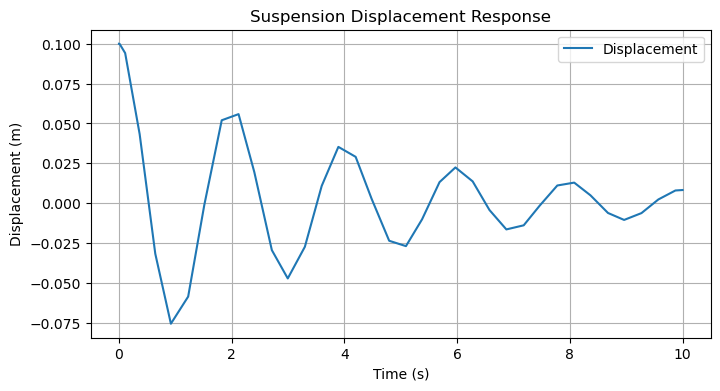

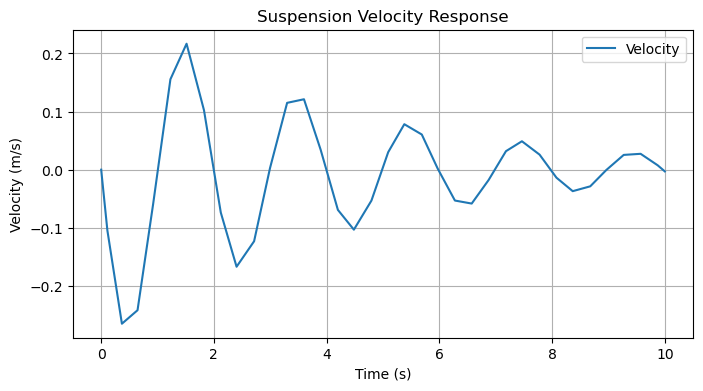

In [4]:

# Plot displacement
graph.figure(figsize=(8, 4))
graph.plot(time, displacement, label="Displacement")
graph.xlabel("Time (s)")
graph.ylabel("Displacement (m)")
graph.title("Suspension Displacement Response")
graph.grid(True)
graph.legend()
graph.show()

# Plot velocity
graph.figure(figsize=(8, 4))
graph.plot(time, velocity, label="Velocity")
graph.xlabel("Time (s)")
graph.ylabel("Velocity (m/s)")
graph.title("Suspension Velocity Response")
graph.grid(True)
graph.legend()
graph.show()


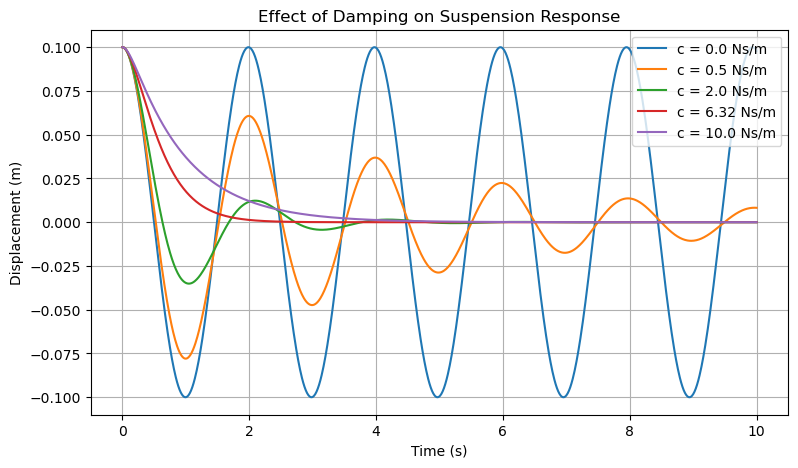

In [9]:

# Compare different damping coefficients

m = 1.0
k = 10.0

damping_values = [0.0, 0.5, 2.0, 6.32, 10.0]

graph.figure(figsize=(9, 5))

for c in damping_values:

    solution = solve_ivp(system, (0, 10), IC, max_step=0.01)

    time = solution.t
    displacement = solution.y[0]

    graph.plot(time, displacement, label=f"c = {c} Ns/m")

graph.xlabel("Time (s)")
graph.ylabel("Displacement (m)")
graph.title("Effect of Damping on Suspension Response")
graph.grid(True)
graph.legend()
graph.show()



### Effect of Damping

Increasing the damping coefficient reduces oscillations and changes how quickly the system returns toward equilibrium.

- **Undamped:** Oscillations continue without decreasing in amplitude.
- **Underdamped:** Oscillations gradually decay.
- **Critically damped:** The system returns toward equilibrium without oscillating and provides the fastest non-oscillatory response.
- **Overdamped:** The system returns without oscillating but more slowly than the critically damped system.

For the baseline system, critical damping occurs at approximately 6.32 Ns/m.


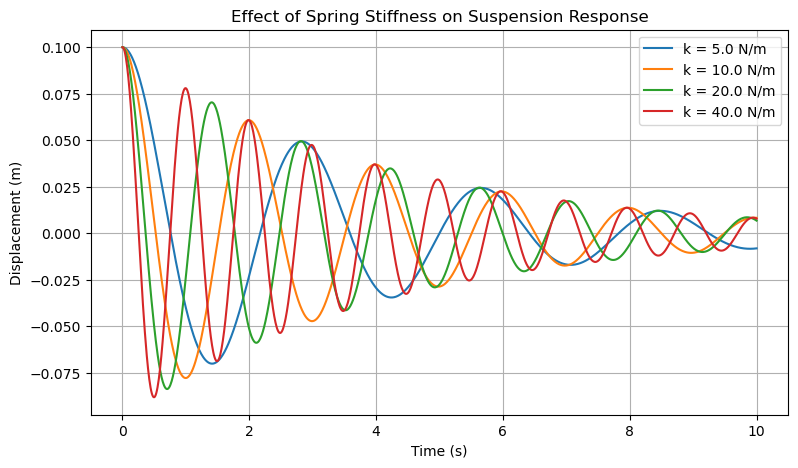

In [11]:

# Compare different spring stiffness values

m = 1.0
c = 0.5

stiffness_values = [5.0, 10.0, 20.0, 40.0]

graph.figure(figsize=(9, 5))

for k in stiffness_values:

    solution = solve_ivp(system, (0, 10), IC, max_step=0.01)

    time = solution.t
    displacement = solution.y[0]

    graph.plot(time, displacement, label=f"k = {k} N/m")

graph.xlabel("Time (s)")
graph.ylabel("Displacement (m)")
graph.title("Effect of Spring Stiffness on Suspension Response")
graph.grid(True)
graph.legend()
graph.show()



### Effect of Spring Stiffness

Increasing spring stiffness increases the system's natural frequency, resulting in faster oscillations.

- **Lower stiffness:** Slower oscillations and a longer oscillation period.
- **Higher stiffness:** Faster oscillations and a shorter oscillation period.
- **Constant damping:** All configurations experience damping, although their damping ratios differ because stiffness changes.

In this simplified model, increasing stiffness does not necessarily reduce settling time, since the damping coefficient remains constant.



## 4. Settling Time Analysis

Settling time is the time required for the system's displacement to enter and remain within a specified tolerance band around equilibrium.

For this analysis, a **5% tolerance** of the initial displacement is used:

$$
x_{\mathrm{tolerance}} = 0.05 \times 0.1 = 0.005 \text{ m}
$$

The system is considered settled once its displacement remains between -0.005 m and +0.005 m for the rest of the simulation.

Settling times are compared for different damping coefficients while mass and spring stiffness remain constant.


In [13]:

# Settling time comparison (5% tolerance)

m = 1.0
k = 10.0

damping_values = [0.0, 0.5, 2.0, 6.32, 10.0]

tolerance = 0.05 * x0
t_eval = np.linspace(0, 10, 1001)

for c in damping_values:

    solution = solve_ivp(
        system, (0, 10), IC,
        t_eval=t_eval
    )

    time = solution.t
    displacement = solution.y[0]

    # Find points outside the tolerance band
    outside = np.where(np.abs(displacement) > tolerance)[0]

    if len(outside) == 0:
        settling_time = 0.0

    elif outside[-1] == len(time) - 1:
        settling_time = None

    else:
        settling_time = time[outside[-1] + 1]

    if settling_time is None:
        print(f"c = {c}: Not settled within 10 seconds")
    else:
        print(f"c = {c}: Settling time = {settling_time:.2f} s")


c = 0.0: Not settled within 10 seconds
c = 0.5: Not settled within 10 seconds
c = 2.0: Settling time = 2.52 s
c = 6.32: Settling time = 1.50 s
c = 10.0: Settling time = 2.78 s



### Settling Time Results

The settling-time comparison demonstrates that increasing damping does not always produce faster settling.

Low damping causes prolonged oscillations, while excessive damping results in a slow return toward equilibrium.

For the tested configurations, damping near the critical value provides a relatively fast response without oscillation.

These conclusions apply to the simplified free-vibration model and should not be interpreted as an optimization of a complete vehicle suspension system.


In [15]:

# Compare settling time and reverse displacement

m = 1.0
k = 10.0

damping_values = [0.0, 0.5, 2.0, 6.32, 10.0]

t_eval = np.linspace(0, 10, 1001)
tolerance = 0.05 * x0

settling_times = []
reverse_displacements = []

for c in damping_values:

    solution = solve_ivp(
        system, (0, 10), IC,
        t_eval=t_eval,
    )

    time = solution.t
    displacement = solution.y[0]

    # Calculate settling time
    outside = np.where(np.abs(displacement) > tolerance)[0]

    if len(outside) == 0:
        settling_time = 0.0

    elif outside[-1] == len(time) - 1:
        settling_time = np.nan

    else:
        settling_time = time[outside[-1] + 1]

    # Maximum displacement past equilibrium
    reverse_displacement = max(0, -np.min(displacement))

    settling_times.append(settling_time)
    reverse_displacements.append(reverse_displacement)

    print(f"c = {c} Ns/m")
    print(f"Settling time: {settling_time:.2f} s")
    print(f"Maximum reverse displacement: {reverse_displacement:.4f} m")
    print()

c = 0.0 Ns/m
Settling time: nan s
Maximum reverse displacement: 0.1000 m

c = 0.5 Ns/m
Settling time: nan s
Maximum reverse displacement: 0.0779 m

c = 2.0 Ns/m
Settling time: 2.52 s
Maximum reverse displacement: 0.0351 m

c = 6.32 Ns/m
Settling time: 1.50 s
Maximum reverse displacement: 0.0000 m

c = 10.0 Ns/m
Settling time: 2.78 s
Maximum reverse displacement: 0.0000 m



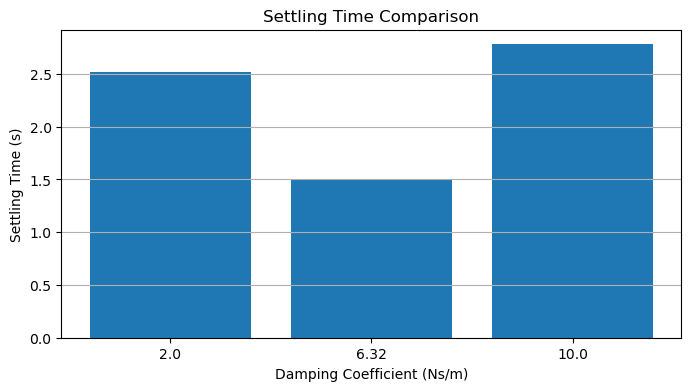

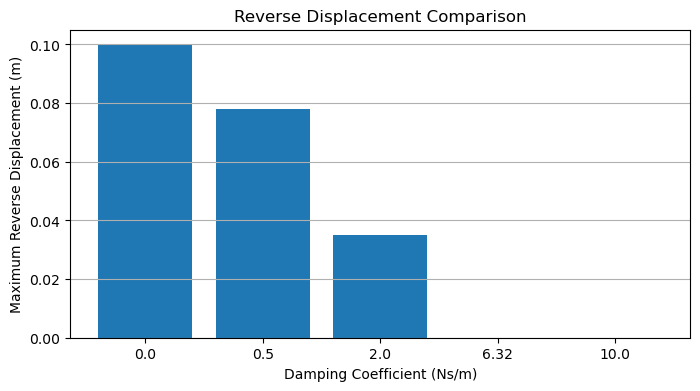

In [17]:

# Compare settling times

graph.figure(figsize=(8, 4))
graph.bar(
    [str(c) for c in damping_values],
    settling_times
)

graph.xlabel("Damping Coefficient (Ns/m)")
graph.ylabel("Settling Time (s)")
graph.title("Settling Time Comparison")
graph.grid(True, axis="y")
graph.show()

# Compare maximum reverse displacement

graph.figure(figsize=(8, 4))
graph.bar(
    [str(c) for c in damping_values],
    reverse_displacements
)

graph.xlabel("Damping Coefficient (Ns/m)")
graph.ylabel("Maximum Reverse Displacement (m)")
graph.title("Reverse Displacement Comparison")
graph.grid(True, axis="y")
graph.show()


### Performance Comparison

The results demonstrate a trade-off between oscillation amplitude and settling time.

- Low damping allows large oscillations and can result in long settling times.
- Increasing damping reduces the maximum displacement past equilibrium.
- Damping near the critical value provides a fast, non-oscillatory response.
- Excessive damping eliminates oscillations but can slow the return to equilibrium.

The comparison highlights why damping must be selected based on the desired dynamic response rather than simply maximized.

**Limitation:** These findings apply to a simplified 1-DOF free-vibration model. Actual vehicle suspension design must also consider road inputs, ride comfort, tire contact, and suspension travel.


## 5. Engineering Conclusions

This project investigated the influence of spring stiffness and damping on the dynamic response of a simplified 1-DOF mass-spring-damper system.

### Key Findings

**1. Spring Stiffness**
- Increasing spring stiffness increases the natural frequency, producing faster oscillations.
- Lower stiffness results in slower oscillations.
- When mass and damping remain constant, the exponential decay rate is unchanged for the tested underdamped configurations.

**2. Damping Coefficient**
- Low damping produces larger oscillations and a slower decay toward equilibrium.
- Increasing damping reduces oscillations and maximum reverse displacement.
- Critical damping provides the fastest non-oscillatory return to equilibrium.
- Excessive damping produces a slower response despite eliminating oscillations.

**3. Settling Time**
- The 5% settling-time analysis provides a quantitative comparison between damping configurations.
- A higher damping coefficient does not always lead to a shorter settling time.
- Damping selection therefore involves balancing response speed and oscillatory behavior.

### Model Limitations

The simulation uses a simplified linear 1-DOF model with several assumptions:

- Constant mass, spring stiffness, and damping coefficient.
- No external forcing or road disturbances.
- No tire stiffness or unsprung mass.
- No suspension geometry or nonlinear behavior.
- No experimental validation against a physical vehicle.

Therefore, the results demonstrate fundamental vibration behavior rather than the performance of a complete automotive suspension.

### Future Development

Possible extensions include:

- Creating a 3D suspension representation using PTC Creo.
- Extending the simulation to a 2-DOF quarter-car model.
- Introducing road-profile inputs to evaluate suspension response.
- Comparing ride comfort and tire contact behavior.

These extensions are outside the scope of the current simulation.
